In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

train_df = pd.read_csv(r"c:\Users\MF\Downloads\Task4\twitter_training.csv", header=None)
val_df = pd.read_csv(r"c:\Users\MF\Downloads\Task4\twitter_validation.csv", header=None)

df = pd.concat([train_df, val_df], ignore_index=True)

print("Shape before renaming:", df.shape)
display(df.head())

if df.shape[1] == 4:
  df.columns = ["Tweet_ID", "Entity", "Sentiment", "Tweet_Text"]

print("\nColumns:", df.columns.tolist())
print("\nClass distribution (Sentiment):")
print(df["Sentiment"].value_counts(dropna=False))

Shape before renaming: (75682, 4)


,0,1,2,3
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...



Columns: ['Tweet_ID', 'Entity', 'Sentiment', 'Tweet_Text']

Class distribution (Sentiment):
Sentiment
Negative      22808
Positive      21109
Neutral       18603
Irrelevant    13162
Name: count, dtype: int64


### 1. Load Dataset & Inspect Class Distribution
Loaded `twitter_training.csv` and `twitter_validation.csv` and combined them into a single dataset of **75,682 rows** and **4 columns** (`Tweet_ID`, `Entity`, `Sentiment`, `Tweet_Text`) so I can perform a clean `80/20` train/test split later:
- **Class distribution:**
  - `Negative`: 22,808
  - `Positive`: 21,109
  - `Neutral`: 18,603
  - `Irrelevant`: 13,162

In [5]:
!pip install nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 3.8 MB/s eta 0:00:01
   ------------------------------ --------- 1.3/1.7 MB 3.7 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 3.6 MB/s  0:00:00

   -------- ------------------------------- 1/5 [regex]
   ---------------- ----------------------- 2/5 [defusedxml]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

print("Missing Tweet_Text before drop:", df["Tweet_Text"].isnull().sum())
df = df.dropna(subset=["Tweet_Text"]).copy()

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


def preprocess_text(text):
  # 1. Lowercase
  text = str(text).lower()
  text = re.sub(r"http\S+|www\S+|https\S+", "", text)
  text = re.sub(r"@\w+|#", "", text)
  text = text.translate(str.maketrans("", "", string.punctuation))
  text = re.sub(r"\d+", "", text)
  tokens = word_tokenize(text)
  clean_tokens = [
      lemmatizer.lemmatize(word)
      for word in tokens
      if word not in stop_words and len(word) > 1
  ]
  return " ".join(clean_tokens)


df["Clean_Text"] = df["Tweet_Text"].apply(preprocess_text)

df = df[df["Clean_Text"].str.strip() != ""].reset_index(drop=True)

print("Shape after text preprocessing:", df.shape)
display(df[["Tweet_Text", "Clean_Text", "Sentiment"]].head())

Missing Tweet_Text before drop: 686
Shape after text preprocessing: (73263, 5)


,Tweet_Text,Clean_Text,Sentiment
0,im getting on borderlands and i will murder yo...,im getting borderland murder,Positive
1,I am coming to the borders and I will kill you...,coming border kill,Positive
2,im getting on borderlands and i will kill you ...,im getting borderland kill,Positive
3,im coming on borderlands and i will murder you...,im coming borderland murder,Positive
4,im getting on borderlands 2 and i will murder ...,im getting borderland murder,Positive


### 2. Text Preprocessing Pipeline
Cleaned and normalized `Tweet_Text` into `Clean_Text` using `NLTK`:
- **Missing & empty rows:** Dropped `686` rows with missing `Tweet_Text` and removed any rows that became empty after preprocessing, leaving **73,263 rows** and **5 columns**.
- **Text cleaning:** Converted text to lowercase, removed URLs, mentions, hashtags, punctuation, and digits, tokenized the text, removed English stopwords, and applied `WordNetLemmatizer`.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X = tfidf.fit_transform(df["Clean_Text"])
y = df["Sentiment"]

print("TF-IDF feature matrix shape:", X.shape)
print("Target (y) shape:", y.shape)

TF-IDF feature matrix shape: (73263, 5000)
Target (y) shape: (73263,)


### 3. Feature Extraction (TF-IDF Vectorizer)
Converted `Clean_Text` into numerical features using `TfidfVectorizer` (`max_features=5000`, `ngram_range=(1, 2)`), producing a feature matrix of shape **(73263, 5000)** and target vector **(73263,)**:
- **Purpose of TF-IDF:** Machine learning models operate on numerical vectors rather than raw strings. **TF-IDF (Term Frequency–Inverse Document Frequency)** highlights words or two-word phrases (`bigrams`) that are frequent in a specific tweet while reducing the weight of words that show up too commonly across the dataset, helping capture stronger sentiment cues.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (58610, 5000)
X_test shape: (14653, 5000)
y_train shape: (58610,)
y_test shape: (14653,)


### 4. Train/Test Split (80/20)
Split the dataset into **80% training** (**58,610** samples) and **20% testing** (**14,653** samples) using `train_test_split` (`test_size=0.20`, `random_state=42`, `stratify=y`) so that all sentiment classes keep a balanced distribution across both sets.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.naive_bayes import MultinomialNB

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, n_jobs=-1),
}

predictions = {}
summary_rows = []

for name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  predictions[name] = y_pred

  acc = accuracy_score(y_test, y_pred)
  prec, rec, f1, _ = precision_recall_fscore_support(
      y_test, y_pred, average="weighted", zero_division=0
  )

  summary_rows.append({
      "Model": name,
      "Accuracy": round(acc, 4),
      "Precision (weighted)": round(prec, 4),
      "Recall (weighted)": round(rec, 4),
      "F1-Score (weighted)": round(f1, 4),
  })

  print("=" * 60)
  print(f"Model: {name}")
  print(f"Accuracy: {acc:.4f}")
  print("\nClassification Report:")
  print(classification_report(y_test, y_pred, zero_division=0))
  print("Confusion Matrix:")
  print(confusion_matrix(y_test, y_pred))

print("\n" + "=" * 60)
print("Summary Comparison Table:")
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

Model: Multinomial Naive Bayes
Accuracy: 0.6391

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.70      0.36      0.48      2557
    Negative       0.63      0.79      0.70      4429
     Neutral       0.65      0.54      0.59      3583
    Positive       0.62      0.74      0.67      4084

    accuracy                           0.64     14653
   macro avg       0.65      0.61      0.61     14653
weighted avg       0.65      0.64      0.63     14653

Confusion Matrix:
[[ 923  674  310  650]
 [ 110 3511  350  458]
 [ 166  786 1929  702]
 [ 123  588  371 3002]]


c:\Users\MF\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Model: Logistic Regression
Accuracy: 0.6888

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.66      0.52      0.58      2557
    Negative       0.72      0.78      0.75      4429
     Neutral       0.66      0.65      0.65      3583
    Positive       0.69      0.73      0.71      4084

    accuracy                           0.69     14653
   macro avg       0.68      0.67      0.67     14653
weighted avg       0.69      0.69      0.69     14653

Confusion Matrix:
[[1320  434  349  454]
 [ 184 3456  411  378]
 [ 232  516 2320  515]
 [ 259  401  427 2997]]

Summary Comparison Table:


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-Score (weighted)
0,Multinomial Naive Bayes,0.6391,0.6460,0.6391,0.6278
1,Logistic Regression,0.6888,0.6868,0.6888,0.6857


### 5 & 6. Model Training & Evaluation
Trained and evaluated two classifiers on the `80/20` split (`14,653` test tweets) using TF-IDF features:
- **Multinomial Naive Bayes:** Achieved **0.6391** accuracy and **0.6278** weighted F1-score.
- **Logistic Regression:** Performed better overall with **0.6888** accuracy, **0.6868** weighted precision, **0.6888** weighted recall, and **0.6857** weighted F1-score.
- **Confusion matrices & per-class metrics:** Both models handled `Negative` and `Positive` well, while `Logistic Regression` showed noticeable gains on `Neutral` and `Irrelevant`.

  error: subprocess-exited-with-error
  
  × Building wheel for wordcloud (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [29 lines of output]
      running bdist_wheel
      running build
      running build_py
      creating build\lib.win-amd64-cpython-315\wordcloud
      copying wordcloud\color_from_image.py -> build\lib.win-amd64-cpython-315\wordcloud
      copying wordcloud\tokenization.py -> build\lib.win-amd64-cpython-315\wordcloud
      copying wordcloud\wordcloud.py -> build\lib.win-amd64-cpython-315\wordcloud
      copying wordcloud\wordcloud_cli.py -> build\lib.win-amd64-cpython-315\wordcloud
      copying wordcloud\_version.py -> build\lib.win-amd64-cpython-315\wordcloud
      copying wordcloud\__init__.py -> build\lib.win-amd64-cpython-315\wordcloud
      copying wordcloud\__main__.py -> build\lib.win-amd64-cpython-315\wordcloud
      running egg_info
      writing wordcloud.egg-info\PKG-INFO
      writing dependency_links to wordcloud.egg-info\dependency

  Using cached wordcloud-1.9.6.tar.gz (27.6 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Failed to build wordcloud


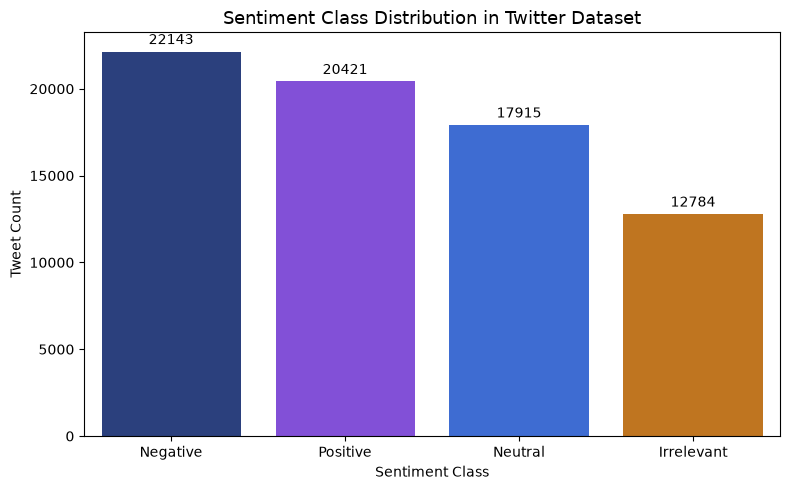

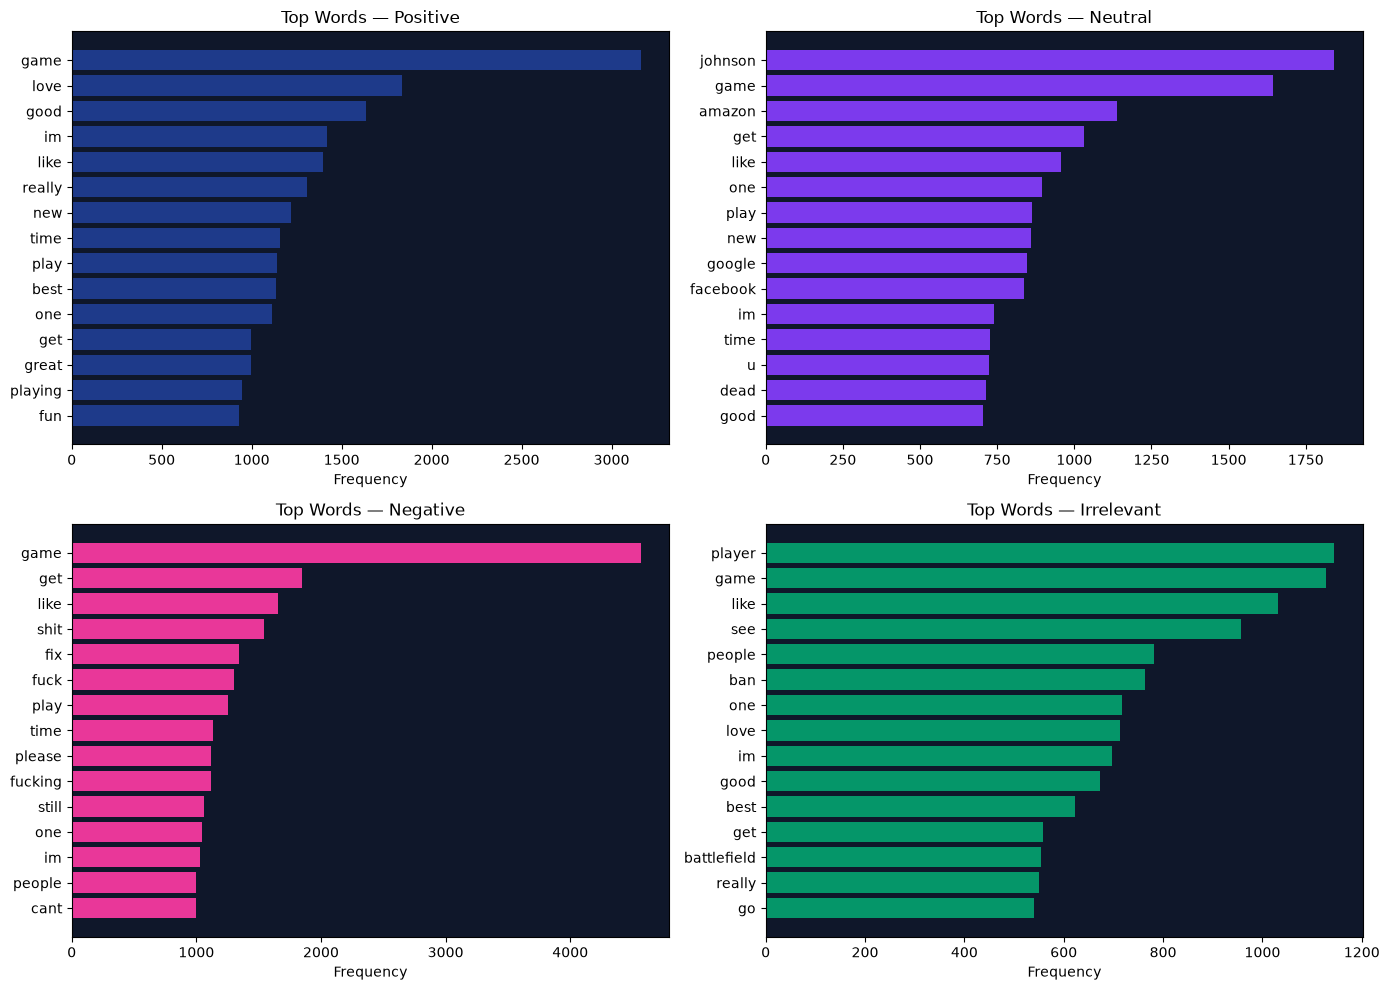

In [14]:
import sys
!{sys.executable} -m pip install wordcloud

try:
    from wordcloud import WordCloud
    use_wc = True
except ImportError:
    use_wc = False
    from collections import Counter

plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x="Sentiment",
    order=df["Sentiment"].value_counts().index,
    palette=["#1E3A8A", "#7C3AED", "#2563EB", "#D97706"]
)
plt.title("Sentiment Class Distribution in Twitter Dataset", fontsize=13)
plt.xlabel("Sentiment Class")
plt.ylabel("Tweet Count")
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

sentiments = df["Sentiment"].unique()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

palettes = ["Blues", "Purples", "Pinks", "Greens"]
colors = ["#1E3A8A", "#7C3AED", "#E93799", "#059669"]

for idx, sent in enumerate(sentiments):
    text_data = " ".join(df[df["Sentiment"] == sent]["Clean_Text"].dropna())
    if use_wc:
        wc = WordCloud(
            width=600,
            height=350,
            background_color="#0F172A",
            colormap=palettes[idx % len(palettes)],
            max_words=100
        ).generate(text_data)
        axes[idx].imshow(wc, interpolation="bilinear")
        axes[idx].axis("off")
    else:
        top_words = Counter(text_data.split()).most_common(15)[::-1]
        words, counts = zip(*top_words)
        axes[idx].barh(words, counts, color=colors[idx % len(colors)])
        axes[idx].set_facecolor("#0F172A")
        axes[idx].set_xlabel("Frequency")
    axes[idx].set_title(f"Top Words — {sent}", fontsize=12)

for j in range(len(sentiments), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### 7. Visualisation
Visualised the sentiment distribution and top recurring words across classes:
- **Sentiment bar chart:** Shows class counts across the cleaned dataset (`Negative`, `Positive`, `Neutral`, and `Irrelevant`).
- **Top words per sentiment class:** Highlights the most frequent cleaned words in each class so we can see vocabulary patterns across sentiments.

In [15]:
_, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=y
)

lr_preds = predictions["Logistic Regression"]

error_df = pd.DataFrame({
    "Original_Text": df.loc[test_idx, "Tweet_Text"].values,
    "Clean_Text": df.loc[test_idx, "Clean_Text"].values,
    "True_Sentiment": y_test.values,
    "Predicted_Sentiment": lr_preds,
})

misclassified = error_df[
    error_df["True_Sentiment"] != error_df["Predicted_Sentiment"]
]

print("Total misclassified samples in test set:", len(misclassified))
display(misclassified.sample(5, random_state=42))

Total misclassified samples in test set: 4560


,Original_Text,Clean_Text,True_Sentiment,Predicted_Sentiment
1595,Ummm W Wth.....,ummm wth,Negative,Neutral
8437,Cant Tell,cant tell,Positive,Negative
75,Rainbow six quarantine sounding real cute righ...,rainbow six quarantine sounding real cute right,Irrelevant,Positive
11167,Don't feel sorry for me,dont feel sorry,Negative,Neutral
463,Can’t even send a message in peace pic.twitter...,even send message peace pictwittercomhzfwyaogn,Irrelevant,Neutral


### 8. Error Analysis
Inspected **5 misclassified examples** (out of **4,560** errors in the test set) from the **Logistic Regression** model:
- **`Ummm W Wth.....` (`Negative` → `Neutral`):** Very short, informal text with filler letters gives weak sentiment signals.
- **`Cant Tell` (`Positive` → `Negative`):** Words like `cant` often carry negative weight in training data, misleading the classifier on brief phrases.
- **`Rainbow six quarantine sounding real cute righ...` (`Irrelevant` → `Positive`):** Positive-sounding words like `cute` push the model toward `Positive` even when the label is `Irrelevant`.
- **`Don't feel sorry for me` (`Negative` → `Neutral`):** Short length and negation (`dont feel sorry`) make boundary separation between `Negative` and `Neutral` harder.
- **`Can’t even send a message in peace pic.twitter...` (`Irrelevant` → `Neutral`):** Leftover URL/image strings and everyday phrasing cause confusion between `Irrelevant` and `Neutral`.

### 9. Conclusion
- **Best Performing Model:** **Logistic Regression** outperformed **Multinomial Naive Bayes** across evaluation metrics, achieving **0.6888** accuracy and a **0.6857** weighted F1-score compared to **0.6391** accuracy and **0.6278** weighted F1-score for Multinomial Naive Bayes.
- **Real-World Application:** A sentiment classification pipeline like this can power **real-time brand monitoring and customer feedback analytics**—helping companies track public opinion on social media or reviews, spot negative complaints early, and prioritise customer support and product improvements.